# El Niño Stress Test: Coffee from Rondônia to California

> **Disclaimer.** This is a static version of the notebook. Its figures and tables were produced with code and data that are not in this repository, so it cannot be run from here. If you would like more detail, or to run it on your own assets, please contact our team at [contact@alpha-klima.com](mailto:contact@alpha-klima.com).

Café da Manhã is a fictitious Robusta coffee producer in Rondônia, Brazil. It grows coffee on 5,000 ha in three fields, processes it in four plants and ships green coffee in containers to buyers in California: by barge down the Madeira river to Manaus, then by sea through the Panama Canal to Long Beach.

This notebook follows one chain: from the El Niño signal in the Pacific, to the hazards it brings to the fields, the plants, the river and the canal, to the numbers a risk or finance team can use.

> **Very strong El Niño scenario, 2027 export year.** The range of outcomes for the company's 2027 harvest and export season *if* the 2026-27 El Niño peaks at about +2.0 to +2.8 °C, as NOAA's September 2026 outlook expects. Built from our climate indicators plus the anomalies observed in past events of the same strength, in today's climate. It is a conditional stress scenario: not a forecast of what will happen, and not a long-term climate scenario. It is compared with a **baseline**, a neutral year in today's climate, and with an intermediate case, **any El Niño** (a peak of +1.0 °C or more, strength unknown), which shows what knowing the strength of the event is worth.

**Sections**

0. Data and settings
1. The signal: El Niño strength, past events and the current outlook
2. El Niño at our sites in past events
3. The company: assets, economics and export routes
4. Building the scenarios
5. Drought: from SPEI to coffee yield and revenue
6. Wildfire: fields and plants
7. Heat: work loss in plants and warehouses
8. Logistics: Madeira and Panama as capacity constraints
9. From channels to EBITDA
10. Loss distribution and tail risk
11. Decisions while there is still time
12. Traceability and sources

## 0. Data and settings

The climate series come mainly from Alpha-Klima's climate data store. Our SPEI drought index and Fire Weather Index are available on the platform as aggregated layers; the site-level time series used here, like the ERA5-Land weather (Copernicus) and MODIS burned area (NASA) behind them, come from the data store and are not publicly available at the moment. They are complemented by public sources: NOAA's El Niño index and outlook, the Porto Velho river gauge of Brazil's National Water Agency (ANA), IBGE's municipal coffee yields and the Panama Canal Authority's operations record. The company's economics and routes are case assumptions. Full sources are listed at the end.

In [1]:
import sys
from pathlib import Path

NOTEBOOKS_ROOT = Path.cwd().parent
if str(NOTEBOOKS_ROOT) not in sys.path:
    sys.path.insert(0, str(NOTEBOOKS_ROOT))

import warnings

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display

from auxiliary_functions import tail_metrics as tm

# Case-specific modules, not included in this repository (see the disclaimer at the top)
from auxiliary_functions import el_nino_case as enc
from auxiliary_functions import el_nino_sim as sim

warnings.filterwarnings("ignore", category=RuntimeWarning)
pio.renderers.default = "notebook+png"
pd.set_option("display.width", 160)

### Scenario settings

NOAA defines an El Niño as an Oceanic Niño Index (ONI) of at least +0.5 °C over five overlapping three-month periods. Event strength follows the widely used classes for the ONI peak: weak from +0.5, moderate from +1.0, strong from +1.5 and very strong from +2.0 °C. The scenario uses the very strong class, and the baseline uses neutral seasons only (no El Niño peak of +1.0 °C or more).

In [2]:
CASE_FILE = "../../resources/cafe_da_manha.json"

SCENARIO = {
    "name": "Very strong El Niño scenario",
    "subtitle": "Conditional on a very strong El Niño · today's climate",
    "current_event": "2026-27",
    "noaa_outlook": "NOAA CPC, 10 Sep 2026: >90% chance of a very strong El Niño this winter; 75% chance of a historic one (ONI above +2.5 °C)",
    "n_simulations": 1000,
    "seed": 2026,
    "refresh_climate": False,
}

CLASS_ORDER = ["Other years", "Moderate", "Strong", "Very strong"]
CLASS_COLORS = {"Other years": "#adb5bd", "Moderate": "#f0a04b", "Strong": "#d9730d", "Very strong": "#9c3500"}
SCEN_COLORS = {"Baseline": "#868e96", "Any El Niño": "#f0a04b", "Very strong El Niño": "#9c3500"}
CH_COLORS = {
    "Drought (yield)": "#2a78d6",
    "Wildfire (fields)": "#eb6834",
    "Logistics (Madeira, Panama)": "#1baf7a",
    "Heat (work loss)": "#eda100",
    "Wildfire (plants)": "#e87ba4",
}
PALETTE = {"ink": "#111111", "ink2": "#4f4f4f", "muted": "#868e96", "grid": "#dee2e6", "axis": "#adb5bd", "surface": "#fcfcfb", "blue": "#1c7ed6", "green": "#2f9e44"}
CHANNELS = dict(sim.LOSS_COMPONENTS)

In [3]:
def style_plot(fig, title, subtitle="", height=460, width=None):
    "Shared layout: title with subtitle, recessive grid and axes."
    t = "<b>" + title + "</b>"
    if subtitle:
        t += "<br><span style='font-size:12px;color:" + PALETTE["ink2"] + "'>" + subtitle + "</span>"
    fig.update_layout(
        title=dict(text=t, font=dict(size=18, color=PALETTE["ink"])),
        font=dict(family="system-ui, -apple-system, Segoe UI, sans-serif", size=13, color=PALETTE["ink2"]),
        paper_bgcolor=PALETTE["surface"], plot_bgcolor=PALETTE["surface"],
        height=height, width=width,
        margin=dict(t=100, b=60, l=70, r=30),
        legend=dict(orientation="h", yanchor="bottom", y=-0.28, x=0, font=dict(color=PALETTE["ink2"])),
    )
    fig.update_xaxes(gridcolor=PALETTE["grid"], zeroline=False, linecolor=PALETTE["axis"], tickfont=dict(color=PALETTE["muted"]))
    fig.update_yaxes(gridcolor=PALETTE["grid"], zeroline=False, linecolor=PALETTE["axis"], tickfont=dict(color=PALETTE["muted"]))
    return fig


usd_m = lambda x: x / 1e6

## 1. The signal

El Niño is measured in the tropical Pacific, thousands of kilometres from Rondônia. NOAA's Oceanic Niño Index (ONI) is the three-month average sea surface temperature anomaly in the Niño 3.4 region, and an event is classed by its peak. We use it to pick the past events that look like the one now developing. The cell below reads the monthly ONI series from NOAA PSL ([oni.data](https://psl.noaa.gov/data/correlation/oni.data)) and lists every event since 1950 with a peak of at least +1.0 °C. The 2026-27 event is still building: its value so far is shown, and NOAA's outlook gives the expected peak.

In [4]:
oni = enc.fetch_oni()
events = enc.enso_events(oni, min_peak=1.0)
events["status"] = np.where(events["event"] == SCENARIO["current_event"], "Current (still building)", "Past event")
display(events)

,event,peak_year,peak_month,peak_oni,class,status
0,1951-52,1952,Oct 1951,1.15,Moderate,Past event
1,1957-58,1958,Jan 1958,1.81,Strong,Past event
2,1963-64,1964,Nov 1963,1.37,Moderate,Past event
3,1965-66,1966,Oct 1965,1.98,Strong,Past event
4,1968-69,1969,Jan 1969,1.13,Moderate,Past event
5,1972-73,1973,Dec 1972,2.12,Very strong,Past event
6,1982-83,1983,Dec 1982,2.23,Very strong,Past event
7,1986-87,1987,Jan 1987,1.23,Moderate,Past event
8,1987-88,1988,Aug 1987,1.70,Strong,Past event
9,1991-92,1992,Jan 1992,1.71,Strong,Past event


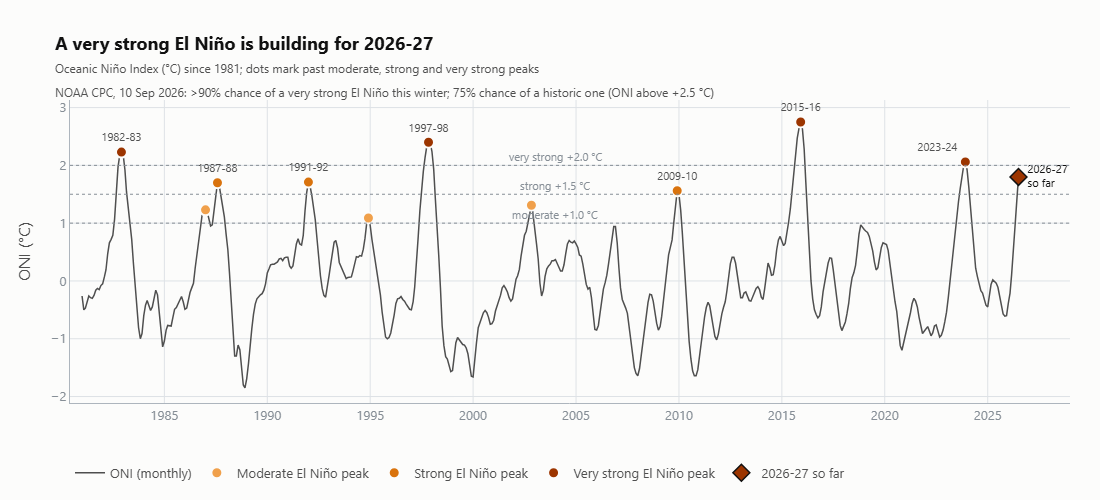

In [5]:
recent = oni["1981-01-01":]
fig = go.Figure()
fig.add_trace(go.Scatter(x=recent.index, y=recent.values, mode="lines", line=dict(color=PALETTE["ink2"], width=1.5),
                         name="ONI (monthly)", hovertemplate="%{x|%b %Y}: %{y:+.2f} °C<extra></extra>"))
for level, label in [(1.0, "moderate +1.0 °C"), (1.5, "strong +1.5 °C"), (2.0, "very strong +2.0 °C")]:
    fig.add_hline(y=level, line=dict(color=PALETTE["muted"], width=1, dash="dot"))
    fig.add_annotation(x="2004-01-01", y=level, text=label, showarrow=False, yshift=9, font=dict(color=PALETTE["muted"], size=11))
shown = events[(events["peak_year"] >= 1982) & (events["status"] == "Past event")]
for cls in ["Moderate", "Strong", "Very strong"]:
    sub = shown[shown["class"] == cls]
    fig.add_trace(go.Scatter(
        x=pd.to_datetime(sub["peak_month"], format="%b %Y"), y=sub["peak_oni"], mode="markers" if cls == "Moderate" else "markers+text",
        marker=dict(size=11, color=CLASS_COLORS[cls], line=dict(color=PALETTE["surface"], width=2)),
        text=sub["event"], textposition=["top left" if e == "2023-24" else "top center" for e in sub["event"]],
        textfont=dict(size=11, color=PALETTE["ink2"]), name=f"{cls} El Niño peak", hovertemplate="%{text}: peak %{y:+.2f} °C<extra></extra>"))
last = oni.index.max().strftime("%Y-%m-%d")
fig.add_trace(go.Scatter(x=[last], y=[oni.iloc[-1]], mode="markers+text",
                         marker=dict(size=13, color=CLASS_COLORS["Very strong"], symbol="diamond", line=dict(color=PALETTE["ink"], width=1.5)),
                         text=[f"{SCENARIO['current_event']}<br>so far"], textposition="middle right", textfont=dict(size=11, color=PALETTE["ink"]),
                         name=f"{SCENARIO['current_event']} so far", hovertemplate="%{x|%b %Y}: %{y:+.2f} °C<extra></extra>"))
style_plot(fig, "A very strong El Niño is building for 2026-27",
           "Oceanic Niño Index (°C) since 1981; dots mark past moderate, strong and very strong peaks<br>" + SCENARIO["noaa_outlook"], height=500, width=1100)
fig.update_xaxes(range=["1980-06-01", "2028-12-31"])
fig.update_yaxes(title="ONI (°C)")
fig.show()

## 2. El Niño at our sites in past events

A strong signal in the Pacific only matters if it reaches the company. This section checks, for each past event since 1986, what happened at the places the chain depends on, each read in the season the event affects:

- **Fields, drought:** the mean 3-month SPEI over October to March of the peak year, the rainy season when the coffee fills its fruit. It is the same quantity the yield model and the El Niño markup use. SPEI below −1 is a moderate drought and below −2 an extreme one. Source: Alpha-Klima's SPEI dataset at the three fields.
- **Madeira, low water:** the lowest river stage between August and November of the peak year at the Porto Velho gauge (ANA station 15400000). Navigation is restricted below 4 m and barges stop at about 2 m.
- **Panama Canal, rainfall:** May to December rainfall in the canal watershed in the year the event starts, against the 1991-2020 average (ERA5-Land). Rain in that season fills the lakes that feed the locks. Reanalysis smooths local rainfall, so the canal link in section 8 is calibrated on the canal's operations record.

In [6]:
case = enc.load_case(CASE_FILE)
signal = sim.observed_signal()
past = signal[signal["class"] != "Other years"]
display(past.drop(columns="farm_spei6_mar").round(2))

summary = signal.groupby("class").agg(
    seasons=("farm_spei3_oct_mar", "size"),
    farm_spei3_mean=("farm_spei3_oct_mar", "mean"), farm_spei3_worst=("farm_spei3_oct_mar", "min"),
    madeira_stage_mean=("madeira_min_stage_m", "mean"), madeira_stage_worst=("madeira_min_stage_m", "min"),
    madeira_days_below_2m=("madeira_days_below_2m", "mean"),
    panama_rain_mean=("panama_rain_anomaly_pct", "mean"), panama_rain_worst=("panama_rain_anomaly_pct", "min"),
).reindex(CLASS_ORDER)
display(summary.round(2))

,class,farm_spei3_oct_mar,madeira_min_stage_m,madeira_days_below_2m,panama_rain_anomaly_pct
peak_year,,,,,
1987,Moderate,-1.57,2.67,0,-11.77
1988,Strong,0.58,2.48,0,-0.97
1992,Strong,-0.63,4.91,0,-2.39
1995,Moderate,-0.01,2.30,0,3.14
1998,Very strong,-1.15,2.53,0,-17.55
2003,Moderate,-0.89,2.62,0,-9.58
2010,Strong,0.27,2.28,0,-2.01
2016,Very strong,-1.09,1.93,2,-13.48
2024,Very strong,-1.87,0.27,85,-7.02


,seasons,farm_spei3_mean,farm_spei3_worst,madeira_stage_mean,madeira_stage_worst,madeira_days_below_2m,panama_rain_mean,panama_rain_worst
class,,,,,,,,
Other years,30,0.16,-0.95,2.82,1.12,5.3,1.85,-8.59
Moderate,3,-0.82,-1.57,2.53,2.30,0.0,-6.07,-11.77
Strong,3,0.08,-0.63,3.22,2.28,0.0,-1.79,-2.39
Very strong,3,-1.37,-1.87,1.58,0.27,29.0,-12.68,-17.55


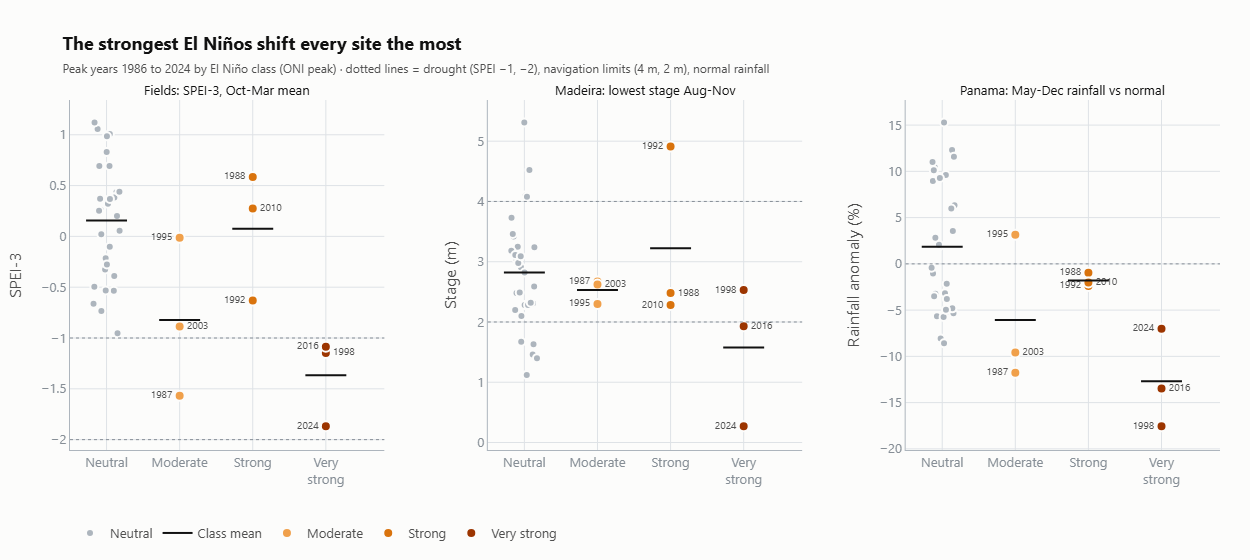

In [7]:
panels = [
    ("farm_spei3_oct_mar", "Fields: SPEI-3, Oct-Mar mean", "SPEI-3", [-1.0, -2.0]),
    ("madeira_min_stage_m", "Madeira: lowest stage Aug-Nov", "Stage (m)", [4.0, 2.0]),
    ("panama_rain_anomaly_pct", "Panama: May-Dec rainfall vs normal", "Rainfall anomaly (%)", [0.0]),
]
fig = make_subplots(rows=1, cols=3, subplot_titles=[p[1] for p in panels], horizontal_spacing=0.09)
rng = np.random.default_rng(7)
for col, (var, _, ytitle, refs) in enumerate(panels, start=1):
    for i, cls in enumerate(CLASS_ORDER):
        sub = signal[signal["class"] == cls].dropna(subset=[var])
        is_event = cls != "Other years"
        jitter = np.zeros(len(sub)) if is_event else rng.uniform(-0.18, 0.18, len(sub))
        fig.add_trace(go.Scatter(
            x=i + jitter, y=sub[var], mode="markers+text" if is_event else "markers",
            marker=dict(size=10 if is_event else 8, color=CLASS_COLORS[cls], line=dict(color=PALETTE["surface"], width=2)),
            text=[str(y) for y in sub.index] if is_event else None,
            textposition=[("middle right" if k % 2 == 0 else "middle left") for k in sub[var].rank(method="first").astype(int)] if is_event else "middle right",
            textfont=dict(size=10, color=PALETTE["ink2"]), name="Neutral" if cls == "Other years" else cls, legendgroup=cls, showlegend=(col == 1),
            customdata=sub.index, hovertemplate="%{customdata}: %{y:.2f}<extra>" + cls + "</extra>"), row=1, col=col)
        if len(sub):
            m = sub[var].mean()
            fig.add_trace(go.Scatter(x=[i - 0.28, i + 0.28], y=[m, m], mode="lines", line=dict(color=PALETTE["ink"], width=2),
                                     name="Class mean", legendgroup="mean", showlegend=(col == 1 and i == 0), hovertemplate=f"{cls} mean: {m:.2f}<extra></extra>"), row=1, col=col)
    for r in refs:
        fig.add_hline(y=r, line=dict(color=PALETTE["muted"], width=1, dash="dot"), row=1, col=col)
    fig.update_xaxes(tickvals=[0, 1, 2, 3], ticktext=["Neutral", "Moderate", "Strong", "Very<br>strong"], tickangle=0, range=[-0.5, 3.8], row=1, col=col)
    fig.update_yaxes(title=ytitle, row=1, col=col)
style_plot(fig, "The strongest El Niños shift every site the most",
           "Peak years 1986 to 2024 by El Niño class (ONI peak) · dotted lines = drought (SPEI −1, −2), navigation limits (4 m, 2 m), normal rainfall", height=560, width=1250)
fig.update_annotations(font=dict(size=13, color=PALETTE["ink"]))
fig.show()

**Reading the chart.** The scenario hinges on the strength of the event. At the fields, the very strong El Niños of 1997-98, 2015-16 and 2023-24 all ended the rainy season in drought. Weaker events are mixed: the three moderate ones were drier than neutral years on average (1986-87 reached drought), and the three strong ones were not. On the Madeira, 2024 set the record low, but the river also runs low in years without El Niño, and its low-water level has been falling for decades, so we treat it as a compound hazard: El Niño on top of a downward trend. In the canal watershed, very strong onset years were clearly drier than normal and weaker ones only slightly. Pooling every event would roughly halve the signal, so the rest of the case compares a neutral year with a very strong El Niño year, the kind NOAA expects for 2026-27.

## 3. The company

Café da Manhã's three fields lie in the central Rondônia coffee belt, the state's highest-yielding Robusta area (IBGE crop survey). Each field has a drying and hulling plant; a fourth plant in Porto Velho prepares and containerises the coffee for export. Its economics and locations are case assumptions.

,id,name,type,area_ha,latitude,longitude
0,F1,Field 1 - Cacoal Coffee Farm,Coffee field,2000.0,-11.605,-61.585
1,F2,Field 2 - Alta Floresta Coffee Farm,Coffee field,1500.0,-12.055,-62.165
2,F3,Field 3 - Sao Miguel Coffee Farm,Coffee field,1500.0,-11.815,-62.605
3,P1,Plant 1 - Cacoal Primary Plant,Processing plant,NaN,-11.480,-61.455
4,P2,Plant 2 - Alta Floresta Primary Plant,Processing plant,NaN,-11.935,-62.010
5,P3,Plant 3 - Sao Miguel Primary Plant,Processing plant,NaN,-11.715,-62.705
6,P4,Plant 4 - Porto Velho Central Plant,Processing plant,NaN,-8.755,-63.905


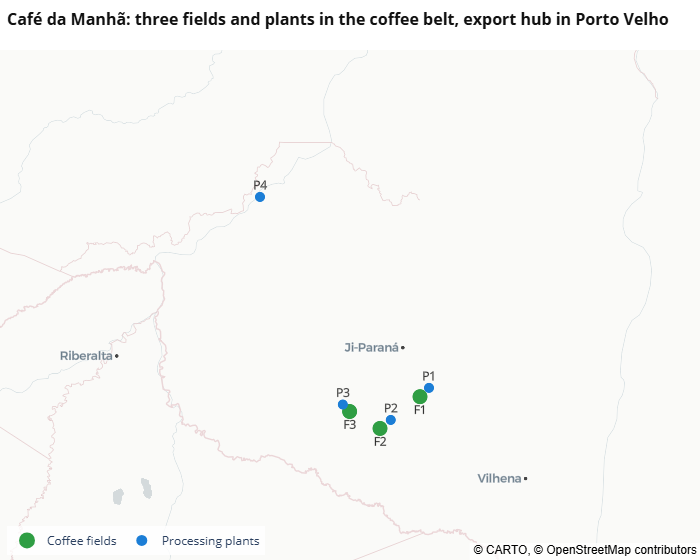

In [8]:
assets = pd.DataFrame(
    [{"id": f["id"], "name": f["name"], "type": "Coffee field", "area_ha": f["area_ha"], "latitude": f["latitude"], "longitude": f["longitude"]} for f in case["fields"]]
    + [{"id": p["id"], "name": p["name"], "type": "Processing plant", "area_ha": np.nan, "latitude": p["latitude"], "longitude": p["longitude"]} for p in case["plants"]]
)
display(assets)

fig = go.Figure()
for kind, color, size, pos in [("Coffee field", PALETTE["green"], 16, "bottom center"), ("Processing plant", PALETTE["blue"], 11, "top center")]:
    sub = assets[assets["type"] == kind]
    fig.add_trace(go.Scattermap(lat=sub["latitude"], lon=sub["longitude"], mode="markers+text", marker=dict(size=size, color=color),
                                text=sub["id"], textposition=pos, textfont=dict(size=12, color=PALETTE["ink"]),
                                name=kind + "s", customdata=sub["name"], hovertemplate="%{customdata}<extra></extra>"))
fig.update_layout(map=dict(style="carto-positron", zoom=5.6, center=dict(lat=-10.3, lon=-62.6)), height=560, margin=dict(l=0, r=0, t=50, b=0),
                  legend=dict(orientation="h", yanchor="bottom", y=0.01, x=0.01, bgcolor="rgba(255,255,255,0.8)"),
                  title=dict(text="<b>Café da Manhã: three fields and plants in the coffee belt, export hub in Porto Velho</b>", font=dict(size=16, color=PALETTE["ink"]), x=0.01))
fig.show()

In [9]:
base = case["baseline"]
economics = pd.DataFrame(
    [("Area", f"{case['production']['area_ha']:,} ha"), ("Yield", f"{case['production']['yield_bags_per_ha']} bags/ha (60 kg)"),
     ("Production", f"{base['bags']:,.0f} bags = {base['tonnes']:,.0f} t"), ("Price", f"US${case['production']['price_usd_per_bag']}/bag"),
     ("Revenue", f"US${usd_m(base['revenue_usd']):.2f}M")]
    + [(k, f"US${usd_m(v):.2f}M") for k, v in base["costs_usd"].items()]
    + [("Operating costs before logistics", f"US${usd_m(base['opex_usd']):.2f}M"), ("EBITDA before logistics", f"US${usd_m(base['ebitda_pre_logistics_usd']):.2f}M")],
    columns=["item", "value"]).set_index("item")
display(economics)
routes = enc.route_table(case).set_index("route")
display(routes.round(2))

,value
item,
Area,"5,000 ha"
Yield,65 bags/ha (60 kg)
Production,"325,000 bags = 19,500 t"
Price,US$210/bag
Revenue,US$68.25M
Production inputs,US$7.50M
Hard labour,US$15.00M
Intense labour,US$20.00M
Light labour,US$4.00M


,name,usd_per_t,logistics_usd_m,ebitda_usd_m,ebitda_margin_pct,uses_madeira,uses_panama
route,,,,,,,
A,Madeira + Panama,270,5.26,15.48,22.69,True,True
B,Peru + Pacific,325,6.34,14.41,21.12,False,False
C,Madeira + Gulf + rail,400,7.80,12.95,18.97,True,False
D,Santos + Panama,470,9.16,11.58,16.97,False,True
E,Santos + Gulf + rail,525,10.24,10.51,15.40,False,False


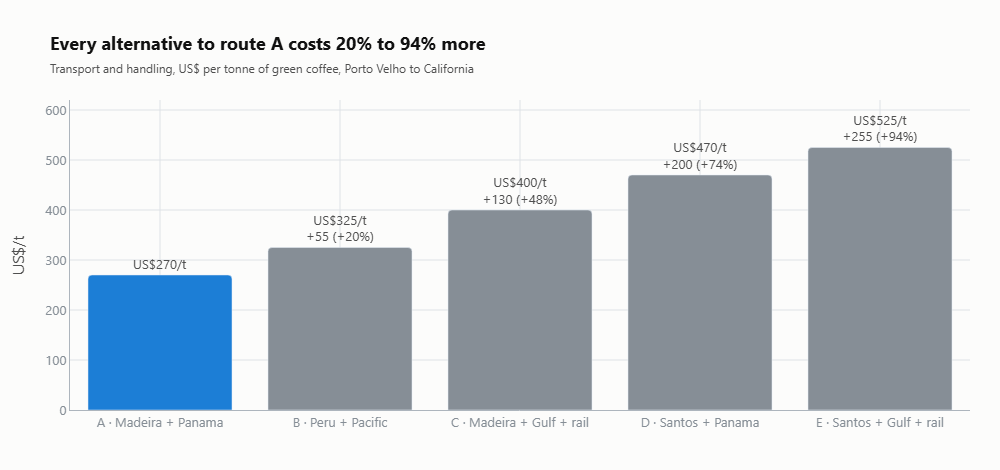

In [10]:
r = routes.reset_index()
extra = r["usd_per_t"] - r.loc[r["route"] == "A", "usd_per_t"].iloc[0]
fig = go.Figure(go.Bar(
    x=r["route"] + " · " + r["name"], y=r["usd_per_t"], marker=dict(color=[PALETTE["blue"]] + [PALETTE["muted"]] * 4, cornerradius=4),
    text=[f"US${v:.0f}/t" + ("" if e == 0 else f"<br>+{e:.0f} (+{100 * e / 270:.0f}%)") for v, e in zip(r["usd_per_t"], extra)],
    textposition="outside", hovertemplate="%{x}: US$%{y:.0f}/t<extra></extra>"))
style_plot(fig, "Every alternative to route A costs 20% to 94% more", "Transport and handling, US$ per tonne of green coffee, Porto Velho to California", height=470, width=1000)
fig.update_yaxes(title="US$/t", range=[0, 620])
fig.show()

Route A, the normal route, leaves an EBITDA of about US$15.5M (22.7% margin). Every alternative avoids the Madeira, the canal or both, at US$55 to US$255 per tonne more. That US$15.5M is the **reference EBITDA**: every loss below is measured against it.

## 4. Building the scenarios

Each scenario is a set of 1,000 simulated years built from what was actually observed at the fields, on the Madeira and in the canal watershed in every season since 1986, so a dry year at the fields stays paired with that year's river and canal conditions. Long-term trends, such as the Madeira's falling low-water level, are first brought to today's level. The El Niño effect is the difference between past El Niños and neutral years, applied on top of the neutral years (the delta-change method, standard in climate impact studies). Three scenarios come out:

- **Baseline:** a neutral year in today's climate.
- **Any El Niño:** an event of +1.0 °C or more whose strength is still unknown, built from all nine such events since 1986.
- **Very strong El Niño:** built from the three very strong events, 1997-98, 2015-16 and 2023-24.

The table shows the markup of each scenario: how far it shifts each hazard against a neutral year.

In [11]:
R = sim.run(case, n=SCENARIO["n_simulations"], seed=SCENARIO["seed"], refresh=SCENARIO["refresh_climate"])
obs, mk = R["observed"], R["markups"]
other, vs = obs["class"] == "Other years", obs["class"] == "Very strong"

def markup_row(label, unit, col, mk_value, ratio=False, note=""):
    base_v = obs.loc[other, col].mean()
    ev = obs.loc[vs, col]
    ev_txt = ", ".join(f"{y}: {(v / base_v - 1) * 100:+.0f}%" if ratio else f"{y}: {v - base_v:+.2f}" for y, v in ev.items())
    return {"indicator": label, "unit": unit, "baseline (today)": round(base_v, 3),
            "very strong markup": (f"{(mk_value - 1) * 100:+.0f}%" if ratio else round(mk_value, 3)), "event anomalies": ev_txt, "note": note}

markup_table = pd.DataFrame([
    markup_row("Fields: SPEI-3, Oct-Mar mean", "index", "spei3_oct_mar_mean", mk["spei3"]),
    markup_row("Madeira: lowest stage, Aug-Nov", "m", "stage_min_aug_nov_m", mk["stage_m"], note="restated to the full-record trend (about −25 cm per decade)"),
    markup_row("Plants: work loss, medium intensity", "fraction", "work_loss_medium", mk["work_loss_medium"], note="restated to the 2026 trend"),
    markup_row("Plants: work loss, low intensity", "fraction", "work_loss_low", mk["work_loss_low"], note="restated to the 2026 trend"),
    markup_row("Panama: May-Dec rainfall anomaly", "%", "panama_rain_anomaly_pct", mk["panama_rain_pct"], note="used to rank years for canal states"),
    markup_row("Fields: fire weather (FWI), Aug-Sep", "index", "fwi_aug_sep", mk["fwi_ratio"], ratio=True, note="as observed; no systematic shift, variability only"),
]).set_index("indicator")
mk_any = R["markups_any"]
markup_table.insert(2, "any El Niño markup", [round(mk_any["spei3"], 3), round(mk_any["stage_m"], 3), round(mk_any["work_loss_medium"], 3),
                                              round(mk_any["work_loss_low"], 3), round(mk_any["panama_rain_pct"], 3), "+0%"])
display(markup_table)

,unit,baseline (today),any El Niño markup,very strong markup,event anomalies,note
indicator,,,,,,
"Fields: SPEI-3, Oct-Mar mean",index,0.155,-0.86,-1.522,"1998: -1.30, 2016: -1.24, 2024: -2.02",
"Madeira: lowest stage, Aug-Nov",m,2.351,-0.485,-1.088,"1998: -0.48, 2016: -0.66, 2024: -2.13",restated to the full-record trend (about −25 c...
"Plants: work loss, medium intensity",fraction,0.298,0.028,0.052,"1998: +0.08, 2016: +0.04, 2024: +0.04",restated to the 2026 trend
"Plants: work loss, low intensity",fraction,0.133,0.02,0.038,"1998: +0.05, 2016: +0.03, 2024: +0.03",restated to the 2026 trend
Panama: May-Dec rainfall anomaly,%,1.853,-8.701,-14.537,"1998: -19.41, 2016: -15.33, 2024: -8.88",used to rank years for canal states
"Fields: fire weather (FWI), Aug-Sep",index,16.930,+0%,+0%,"1998: -52%, 2016: -25%, 2024: +113%","as observed; no systematic shift, variability ..."


Fire weather shows no systematic El Niño shift at the fields (2024 was a record, 1998 and 2016 were below normal), so its markup is zero and only its year-to-year variability enters the scenarios.

## 5. Drought: from SPEI to coffee yield and revenue

Drought reaches the company through yield, and coffee losses accelerate as drought deepens: over 16 years of field trials in Campinas, a 9% shortfall in the crop's water use cost 2.5% of yield, and a 23% shortfall cost 52% (Arruda and Grande, 2003).

Our vulnerability function counts the months of moderate, severe and extreme drought (SPEI-3) between October and March, when the coffee fills its fruit, and gives each category a progressively larger loss, following the structure of Miyamoto and Hackmann (2025). Its level is calibrated on coffee's own record: in the field municipalities, yields fell 13.4% on average in the very strong El Niños of 1997-98, 2015-16 and 2023-24 (IBGE). This agrees with independent evidence for Robusta in Vietnam, where dry seasons yield 10 to 13% less than wet ones (Luong and Bui, 2025). Part of the loss can also land in the following harvest, which the model does not capture.

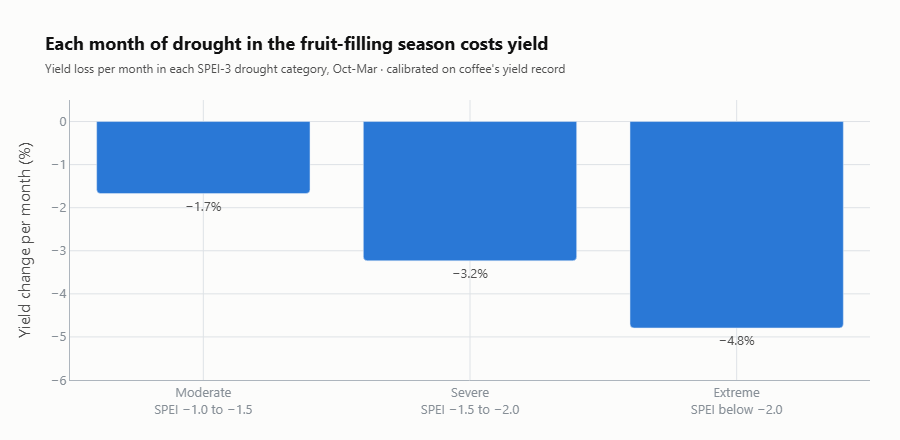

In [12]:
beta = {k: v * R["yield_factor"] for k, v in sim.PARAMS["yield_beta"].items()}
labels = {"moderate": "Moderate<br>SPEI −1.0 to −1.5", "severe": "Severe<br>SPEI −1.5 to −2.0", "extreme": "Extreme<br>SPEI below −2.0"}
fig = go.Figure(go.Bar(x=[labels[k] for k in beta], y=[-100 * v for v in beta.values()], marker=dict(color=CH_COLORS["Drought (yield)"], cornerradius=4),
                       text=[f"−{100 * v:.1f}%" for v in beta.values()], textposition="outside", hovertemplate="%{x}: %{y:.1f}% per month<extra></extra>"))
style_plot(fig, "Each month of drought in the fruit-filling season costs yield",
           "Yield loss per month in each SPEI-3 drought category, Oct-Mar · calibrated on coffee's yield record", height=440, width=900)
fig.update_yaxes(title="Yield change per month (%)", range=[-6, 0.5])
fig.show()

,mean yield loss %,P90 yield loss %,P95 yield loss %,mean revenue loss US$M,share of years with any drought loss %,mean loss % of revenue
scenario,,,,,,
Baseline,1.92,5.02,8.14,1.21,47.9,1.77
Any El Niño,7.23,17.61,19.28,4.55,80.1,6.67
Very strong El Niño,13.09,24.07,25.63,8.25,96.5,12.08


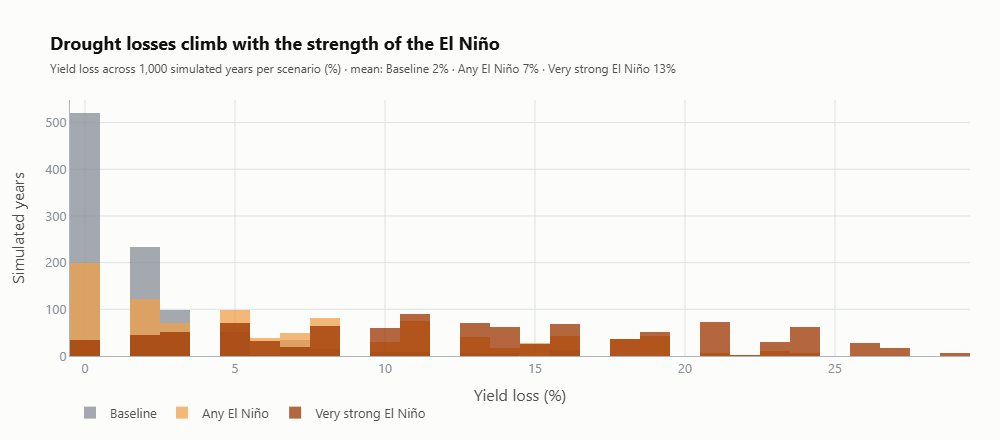

In [13]:
scen = {"Baseline": R["baseline"], "Any El Niño": R["any_el_nino"], "Very strong El Niño": R["el_nino"]}
rows = []
for name, d in scen.items():
    rows.append({"scenario": name, "mean yield loss %": 100 * d["yield_loss"].mean(), "P90 yield loss %": 100 * d["yield_loss"].quantile(0.9),
                 "P95 yield loss %": 100 * d["yield_loss"].quantile(0.95), "mean revenue loss US$M": usd_m(d["loss_yield_usd"].mean()),
                 "share of years with any drought loss %": 100 * (d["yield_loss"] > 0).mean()})
drought_table = pd.DataFrame(rows).set_index("scenario")
drought_table["mean loss % of revenue"] = 100 * drought_table["mean revenue loss US$M"] / usd_m(base["revenue_usd"])
display(drought_table.round(2))

fig = go.Figure()
for name, d in scen.items():
    fig.add_trace(go.Histogram(x=100 * d["yield_loss"], xbins=dict(start=-0.5, end=40, size=1), name=name, marker_color=SCEN_COLORS[name], opacity=0.75))
style_plot(fig, "Drought losses climb with the strength of the El Niño", "Yield loss across 1,000 simulated years per scenario (%) · mean: " + " · ".join(f"{n} {100 * d['yield_loss'].mean():.0f}%" for n, d in scen.items()), height=440, width=1000)
fig.update_layout(barmode="overlay")
fig.update_xaxes(title="Yield loss (%)")
fig.update_yaxes(title="Simulated years")
fig.show()

## 6. Wildfire: fields and plants

Fire weather affects both the coffee fields and the buildings, through different vulnerability relationships:

- **Fields:** the share of land that burns each year around each field, observed by satellite since 2001 (earlier seasons estimated from the Fire Weather Index). A burned share of the plantation loses that year's harvest.
- **Plants:** the same burned share around each plant gives the annual probability that a fire reaches the site. As in our platform's generic fire vulnerability curve, a fire that reaches a building destroys 70% of its value, so expected damage = 70% × probability × replacement value. Plant values are case assumptions (US$6M for each primary plant, US$10M for Porto Velho).

The coffee belt is consolidated farmland: around the fields about half a percent of the land burns in an average year, and fire weather shows no systematic El Niño shift here, so this channel stays small in both scenarios. The large Rondônia fires happen further north, on the forest frontier.

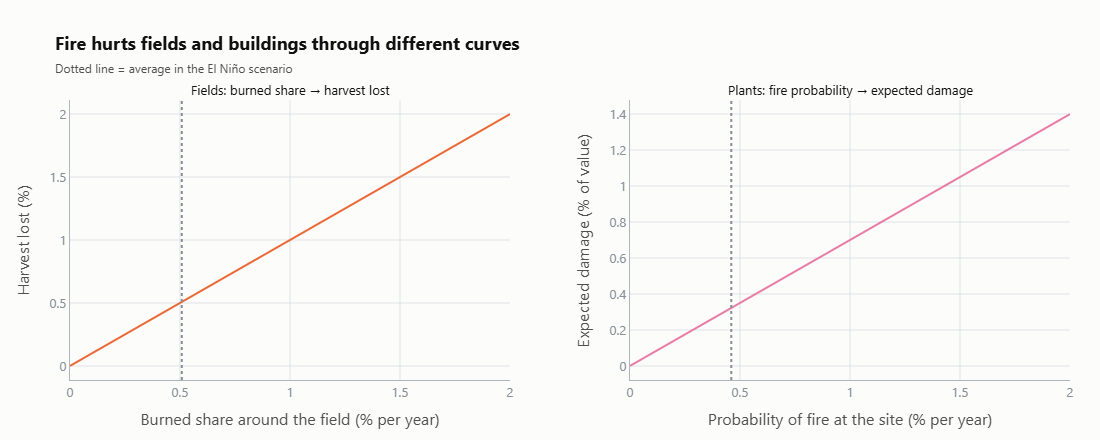

,burned share around fields %,field fire loss US$M,plant fire damage US$M,P95 total fire US$M
scenario,,,,
Baseline,0.510,0.315,0.097,1.487
Any El Niño,0.487,0.287,0.109,1.417
Very strong El Niño,0.508,0.283,0.098,1.315


In [14]:
fig = make_subplots(rows=1, cols=2, subplot_titles=["Fields: burned share → harvest lost", "Plants: fire probability → expected damage"], horizontal_spacing=0.12)
x = np.linspace(0, 2, 50)
fig.add_trace(go.Scatter(x=x, y=x, mode="lines", line=dict(color=CH_COLORS["Wildfire (fields)"], width=2), name="Fields", showlegend=False), row=1, col=1)
fig.add_trace(go.Scatter(x=x, y=sim.PARAMS["plant_fire_damage_ratio"] * x, mode="lines", line=dict(color=CH_COLORS["Wildfire (plants)"], width=2), name="Plants", showlegend=False), row=1, col=2)
for col, d in [(1, R["el_nino"]["burned_share"] * 100), (2, R["el_nino"][[f"plant_fire_prob_{p}" for p in sim.PLANTS]].mean(axis=1) * 100)]:
    fig.add_vline(x=float(d.mean()), line=dict(color=PALETTE["muted"], dash="dot"), row=1, col=col)
fig.update_xaxes(title="Burned share around the field (% per year)", row=1, col=1)
fig.update_xaxes(title="Probability of fire at the site (% per year)", row=1, col=2)
fig.update_yaxes(title="Harvest lost (%)", row=1, col=1)
fig.update_yaxes(title="Expected damage (% of value)", row=1, col=2)
style_plot(fig, "Fire hurts fields and buildings through different curves", "Dotted line = average in the El Niño scenario", height=440, width=1100)
fig.update_annotations(font=dict(size=13, color=PALETTE["ink"]))
fig.show()

fire_table = pd.DataFrame([{"scenario": n, "burned share around fields %": 100 * d["burned_share"].mean(),
                            "field fire loss US$M": usd_m(d["loss_fire_usd"].mean()), "plant fire damage US$M": usd_m(d["loss_plant_fire_usd"].mean()),
                            "P95 total fire US$M": usd_m((d["loss_fire_usd"] + d["loss_plant_fire_usd"]).quantile(0.95))} for n, d in scen.items()]).set_index("scenario")
display(fire_table.round(3))

## 7. Heat: work loss in plants and warehouses

Heat and humidity reduce how much work people can do. We use the same work-loss function as our heat-stress dataset: wet-bulb globe temperature (WBGT) from daily mean temperature and humidity, turned into a share of work capacity lost for each work intensity. It is applied to ERA5-Land weather at the four plants.

Two rules keep this channel honest. First, field labour (the hard and intense labour lines, US$35M) gets no work loss, because the empirical yield response in section 5 already includes whatever heat did to field crews. Second, as in our vulnerability model, only the **change** in work loss against a normal year is used, not its level. The light-labour line (US$4M) is split 75% plants and warehouses (medium intensity) and 25% admin (low intensity). Extra labour cost = change in work loss × that cost.

,"change in work loss, medium (pp)","change in work loss, low (pp)",extra labour cost US$M,% of light labour cost
scenario,,,,
Baseline,-0.08,-0.03,0.03,0.76
Any El Niño,2.84,2.07,0.11,2.71
Very strong El Niño,5.25,3.79,0.20,4.88


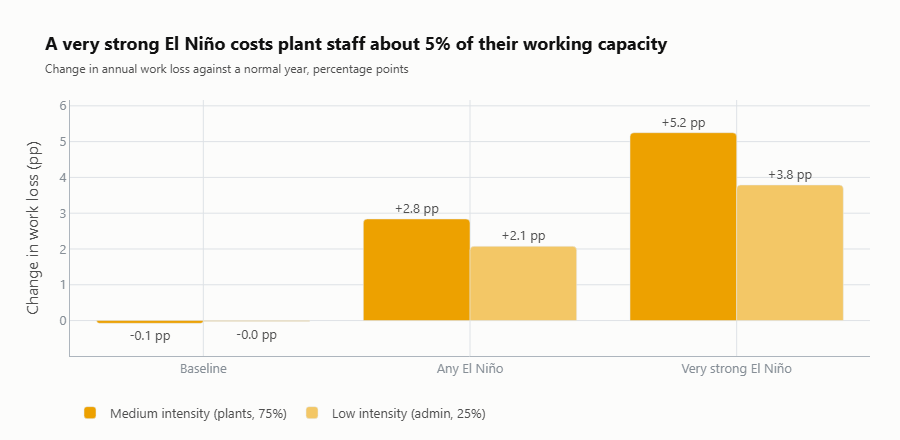

In [15]:
heat_table = pd.DataFrame([{"scenario": n, "change in work loss, medium (pp)": 100 * d["d_work_loss_medium"].mean(),
                            "change in work loss, low (pp)": 100 * d["d_work_loss_low"].mean(),
                            "extra labour cost US$M": usd_m(d["loss_labour_usd"].mean()),
                            "% of light labour cost": 100 * d["loss_labour_usd"].mean() / base["costs_usd"]["Light labour"]} for n, d in scen.items()]).set_index("scenario")
display(heat_table.round(2))

fig = go.Figure()
for intensity, col in [("Medium intensity (plants, 75%)", "d_work_loss_medium"), ("Low intensity (admin, 25%)", "d_work_loss_low")]:
    fig.add_trace(go.Bar(x=list(scen), y=[100 * d[col].mean() for d in scen.values()], name=intensity,
                         text=[f"{100 * d[col].mean():+.1f} pp" for d in scen.values()], textposition="outside",
                         marker=dict(color=CH_COLORS["Heat (work loss)"] if "Medium" in intensity else "#f3c766", cornerradius=4)))
style_plot(fig, "A very strong El Niño costs plant staff about 5% of their working capacity",
           "Change in annual work loss against a normal year, percentage points", height=440, width=900)
fig.update_layout(barmode="group")
fig.update_yaxes(title="Change in work loss (pp)")
fig.show()

## 8. Logistics: Madeira and Panama as capacity constraints

Low water does not close a route at once; it first makes it smaller and more expensive. Two mechanisms feed the routing:

- **Madeira:** each day, the Porto Velho stage sets barge capacity and the cost of the river leg. At 4 m or more barges load fully; between 4 m and 2 m loads fall and the river leg gets progressively more expensive; below 2 m navigation stops. 60% of the coffee ships between August and November, the low-water months.
- **Panama:** three canal states calibrated on the operations record: normal, moderate (draft limits, as in 1998, 2016 and 2019-20) and severe (slot cuts, as in 2023-24), each with less capacity and a higher surcharge. A very strong El Niño makes the moderate and severe states far more likely, and the driest years take the worst state.

Each simulated year then ships its coffee at least cost: the cheapest route first, until its capacity runs out, then the next.

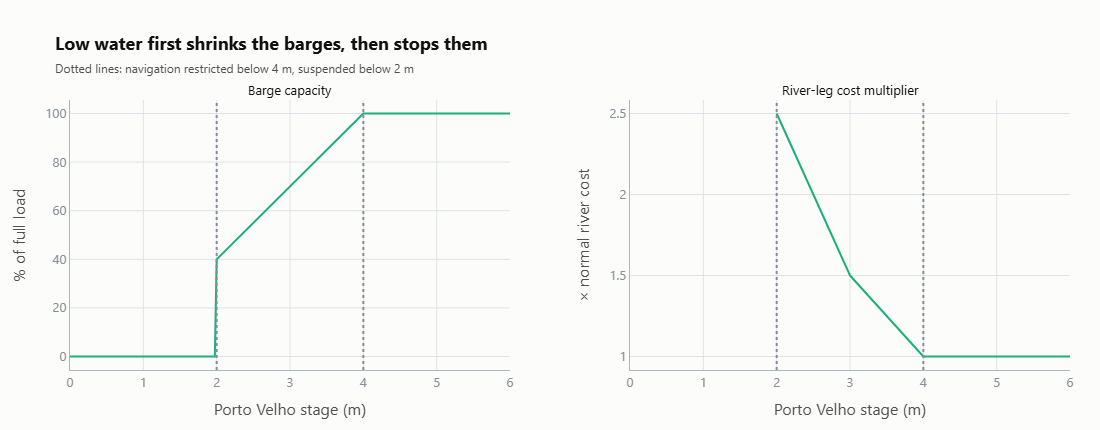

In [16]:
stage = np.linspace(0, 6, 241)
cap = np.interp(stage, sim.PARAMS["river_stage_m"], sim.PARAMS["river_capacity"])
cap[stage < sim.PARAMS["river_closed_below_m"]] = 0
mult = np.where(stage < sim.PARAMS["river_closed_below_m"], np.nan, np.interp(stage, sim.PARAMS["river_stage_m"], sim.PARAMS["river_cost_mult"]))
fig = make_subplots(rows=1, cols=2, subplot_titles=["Barge capacity", "River-leg cost multiplier"], horizontal_spacing=0.12)
fig.add_trace(go.Scatter(x=stage, y=100 * cap, mode="lines", line=dict(color=CH_COLORS["Logistics (Madeira, Panama)"], width=2), showlegend=False), row=1, col=1)
fig.add_trace(go.Scatter(x=stage, y=mult, mode="lines", line=dict(color=CH_COLORS["Logistics (Madeira, Panama)"], width=2), showlegend=False), row=1, col=2)
for col in (1, 2):
    for t in (2.0, 4.0):
        fig.add_vline(x=t, line=dict(color=PALETTE["muted"], dash="dot"), row=1, col=col)
fig.update_xaxes(title="Porto Velho stage (m)", row=1, col=1)
fig.update_xaxes(title="Porto Velho stage (m)", row=1, col=2)
fig.update_yaxes(title="% of full load", row=1, col=1)
fig.update_yaxes(title="× normal river cost", row=1, col=2)
style_plot(fig, "Low water first shrinks the barges, then stops them", "Dotted lines: navigation restricted below 4 m, suspended below 2 m", height=430, width=1100)
fig.update_annotations(font=dict(size=13, color=PALETTE["ink"]))
fig.show()

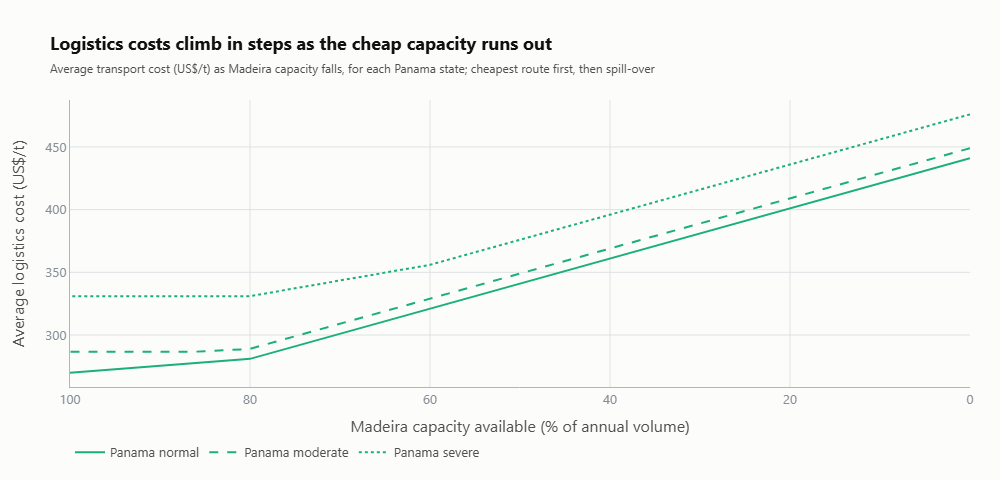

,days below 2 m (Aug-Nov),Madeira capacity %,canal: moderate / severe years %,average cost US$/t,P95 cost US$/t,extra logistics cost US$M
scenario,,,,,,
Baseline,11.1,86.1,8 / 2,289.5,325.1,0.4
Any El Niño,22.4,79.1,22 / 11,304.3,346.4,0.6
Very strong El Niño,38.8,71.0,67 / 33,327.1,362.4,1.0


In [17]:
t0 = base["tonnes"]
river_share = np.linspace(0, 1, 101)
fig = go.Figure()
for state, dash in [("normal", "solid"), ("moderate", "dash"), ("severe", "dot")]:
    st = sim.PARAMS["panama_states"][state]
    y = [sim.route_allocation(case, t0, s * t0, st["capacity"] * t0, 1.0, st["surcharge_usd_t"])["usd_per_t"] for s in river_share]
    fig.add_trace(go.Scatter(x=100 * river_share, y=y, mode="lines", line=dict(color=CH_COLORS["Logistics (Madeira, Panama)"], width=2, dash=dash),
                             name=f"Panama {state}", hovertemplate="river capacity %{x:.0f}%: US$%{y:.0f}/t<extra>" + state + "</extra>"))
style_plot(fig, "Logistics costs climb in steps as the cheap capacity runs out",
           "Average transport cost (US$/t) as Madeira capacity falls, for each Panama state; cheapest route first, then spill-over", height=480, width=1000)
fig.update_xaxes(title="Madeira capacity available (% of annual volume)", autorange="reversed")
fig.update_yaxes(title="Average logistics cost (US$/t)")
fig.show()

logistics_table = pd.DataFrame([{"scenario": n, "days below 2 m (Aug-Nov)": d["madeira_days_below_2m"].mean(),
                                 "Madeira capacity %": 100 * d["river_capacity_share"].mean(),
                                 "canal: moderate / severe years %": f"{100 * (d['panama_state'] == 'moderate').mean():.0f} / {100 * (d['panama_state'] == 'severe').mean():.0f}",
                                 "average cost US$/t": d["logistics_usd_per_t"].mean(), "P95 cost US$/t": d["logistics_usd_per_t"].quantile(0.95),
                                 "extra logistics cost US$M": usd_m(d["loss_logistics_usd"].mean())} for n, d in scen.items()]).set_index("scenario")
display(logistics_table.round(1))

Even a normal year today is not route A all year: with the low-water trend, an average August to November already has close to two weeks below 2 m, so part of the coffee spills onto Peru or the road to Santos. A very strong El Niño more than triples that.

## 9. From channels to EBITDA

Each physical impact lands on one line of the income statement: drought and field fires on revenue (lost tonnes at their margin after route A logistics), plant fires on repair costs, heat on labour costs, and the Madeira and canal on logistics costs above route A. The bridge below starts from the reference EBITDA of a normal year on route A and subtracts the average of each channel in the El Niño scenario.

,US$M,% of reference EBITDA
step,,
Reference EBITDA,15.48,100.00
Drought (yield),-8.25,-53.26
Wildfire (fields),-0.28,-1.83
"Logistics (Madeira, Panama)",-0.96,-6.21
Heat (work loss),-0.20,-1.26
Wildfire (plants),-0.10,-0.63
"EBITDA, very strong El Niño (mean year)",5.70,36.81


,US$M,% of reference EBITDA
step,,
Reference EBITDA,15.48,100.00
Drought (yield),-4.55,-29.40
Wildfire (fields),-0.29,-1.85
"Logistics (Madeira, Panama)",-0.61,-3.95
Heat (work loss),-0.11,-0.70
Wildfire (plants),-0.11,-0.71
"EBITDA, any El Niño (mean year)",9.82,63.39


,US$M,% of reference EBITDA
step,,
Reference EBITDA,15.48,100.00
Drought (yield),-12.14,-78.43
Wildfire (fields),-0.06,-0.38
"Logistics (Madeira, Panama)",-1.64,-10.59
Heat (work loss),-0.14,-0.91
Wildfire (plants),-0.11,-0.72
"EBITDA, 2023-24 replay",1.39,8.97


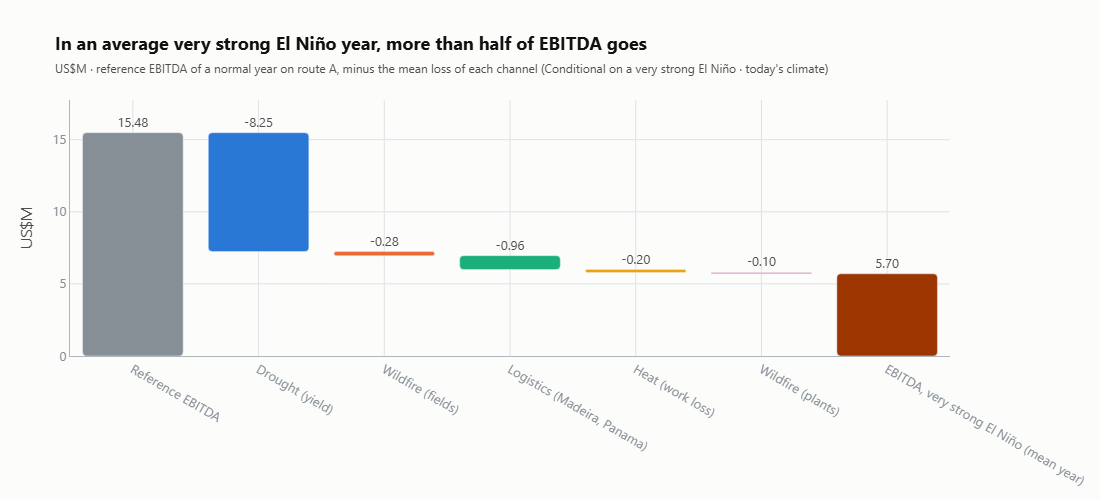

In [18]:
ref = sim.reference_ebitda(case)
order = ["loss_yield_usd", "loss_fire_usd", "loss_logistics_usd", "loss_labour_usd", "loss_plant_fire_usd"]

def bridge(d, name):
    vals = [usd_m(d[c].mean()) for c in order]
    stressed = usd_m(ref) - sum(vals)
    return pd.DataFrame({"step": ["Reference EBITDA"] + [CHANNELS[c] for c in order] + [f"EBITDA, {name}"],
                         "US$M": [usd_m(ref)] + [-v for v in vals] + [stressed],
                         "% of reference EBITDA": [100.0] + [-100 * v / usd_m(ref) for v in vals] + [100 * stressed / usd_m(ref)]}).set_index("step")

bridge_el = bridge(R["el_nino"], "very strong El Niño (mean year)")
bridge_any = bridge(R["any_el_nino"], "any El Niño (mean year)")
bridge_replay = bridge(R["replay_2024"], "2023-24 replay")
display(bridge_el.round(2))
display(bridge_any.round(2))
display(bridge_replay.round(2))

steps = list(bridge_el.index)
vals = bridge_el["US$M"].values
level, bases, heights, colors = usd_m(ref), [], [], []
for i, (step, v) in enumerate(zip(steps, vals)):
    if i == 0 or i == len(steps) - 1:
        bases.append(0.0); heights.append(v)
        colors.append(SCEN_COLORS["Baseline"] if i == 0 else SCEN_COLORS["Very strong El Niño"])
    else:
        level += v
        bases.append(level); heights.append(-v)
        colors.append(CH_COLORS[step])
fig = go.Figure(go.Bar(x=steps, y=heights, base=bases, marker=dict(color=colors, cornerradius=4),
                       text=[f"{v:.2f}" if i in (0, len(steps) - 1) else f"{v:+.2f}" for i, v in enumerate(vals)], textposition="outside",
                       hovertemplate="%{x}: %{text} US$M<extra></extra>"))
style_plot(fig, "In an average very strong El Niño year, more than half of EBITDA goes",
           f"US$M · reference EBITDA of a normal year on route A, minus the mean loss of each channel ({SCENARIO['subtitle']})", height=500, width=1100)
fig.update_yaxes(title="US$M")
fig.show()

## 10. Loss distribution and tail risk

Averages rarely break a company; tail events do. The 1,000 simulated years of each scenario form a loss distribution: the loss of EBITDA against the reference year. Tail metrics follow the conventions of Alpha-Klima's financial module: Value-at-Risk (VaR) is the loss not exceeded in 95% (or 99%) of years, and Expected Shortfall (ES) is the average loss in the years beyond it. The 2023-24 replay, the observed 2023-24 hazards run through the same chain, is marked for reference.

In [19]:
def tail(d, percentiles=(95, 99)):
    loss = d["loss_usd"].values
    edges = np.linspace(min(loss.min(), 0), loss.max() * 1.0001 + 1, 401)
    counts, _ = np.histogram(loss, bins=edges)
    ve = tm.var_es(edges, counts / counts.sum(), percentiles)
    out = {"expected loss": loss.mean(), "P50": np.median(loss)}
    for p, (v, e) in ve.items():
        out[f"VaR {p:.0f}"], out[f"ES {p:.0f}"] = v, e
    return out

metrics = pd.DataFrame({n: tail(d) for n, d in scen.items()}).T
metrics_usd = metrics.apply(usd_m)
metrics_pct = 100 * metrics / ref
print("Expected loss, % of reference EBITDA: " + " → ".join(f"{n} {metrics_pct.loc[n, 'expected loss']:.0f}%" for n in scen))
display(metrics_usd.assign(**{"replay 2023-24": usd_m(R["replay_2024"]["loss_usd"].iloc[0])}).round(2))
display(metrics_pct.round(0).rename(columns=lambda c: c + " (% ref. EBITDA)"))


Expected loss, % of reference EBITDA: Baseline 13% → Any El Niño 37% → Very strong El Niño 63%


,expected loss,P50,VaR 95,ES 95,VaR 99,ES 99,replay 2023-24
Baseline,2.02,1.32,6.63,9.65,10.82,12.49,14.1
Any El Niño,5.67,4.97,13.19,14.49,15.52,16.20,14.1
Very strong El Niño,9.79,9.82,17.08,18.13,18.82,19.37,14.1


,expected loss (% ref. EBITDA),P50 (% ref. EBITDA),VaR 95 (% ref. EBITDA),ES 95 (% ref. EBITDA),VaR 99 (% ref. EBITDA),ES 99 (% ref. EBITDA)
Baseline,13.0,9.0,43.0,62.0,70.0,81.0
Any El Niño,37.0,32.0,85.0,94.0,100.0,105.0
Very strong El Niño,63.0,63.0,110.0,117.0,122.0,125.0


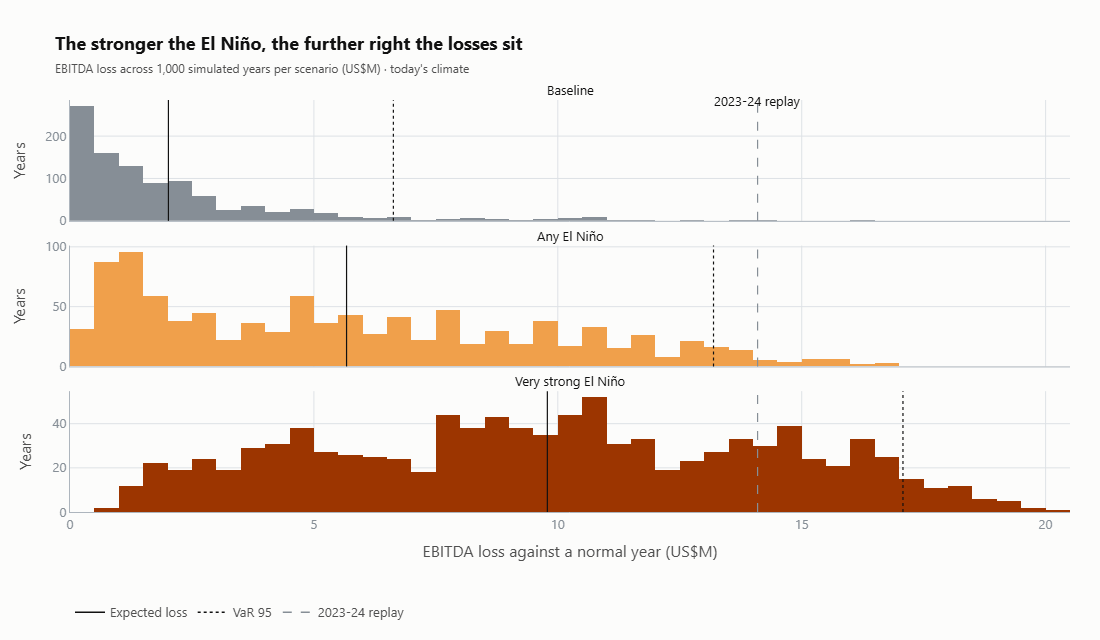

In [20]:
names = list(scen)
fig = make_subplots(rows=len(names), cols=1, shared_xaxes=True, vertical_spacing=0.06, subplot_titles=names)
replay = usd_m(R["replay_2024"]["loss_usd"].iloc[0])
for row, name in enumerate(names, start=1):
    d = scen[name]
    fig.add_trace(go.Histogram(x=usd_m(d["loss_usd"]), xbins=dict(start=-1, end=26, size=0.5), name=name, showlegend=False,
                               marker=dict(color=SCEN_COLORS[name]), hovertemplate="US$%{x}M: %{y} years<extra>" + name + "</extra>"), row=row, col=1)
    for metric, dash in [("expected loss", "solid"), ("VaR 95", "dot")]:
        fig.add_vline(x=metrics_usd.loc[name, metric], line=dict(color=PALETTE["ink"], dash=dash, width=1.2), row=row, col=1)
    fig.add_vline(x=replay, line=dict(color=PALETTE["muted"], dash="dash", width=1.2), row=row, col=1)
    fig.update_yaxes(title="Years", row=row, col=1)
for label, dash, color in [("Expected loss", "solid", PALETTE["ink"]), ("VaR 95", "dot", PALETTE["ink"]), ("2023-24 replay", "dash", PALETTE["muted"])]:
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", line=dict(color=color, dash=dash, width=1.5), name=label), row=1, col=1)
fig.add_annotation(x=replay, y=1, yref="paper", text="2023-24 replay", showarrow=False, yshift=10, font=dict(color=PALETTE["ink2"], size=11))
style_plot(fig, "The stronger the El Niño, the further right the losses sit",
           "EBITDA loss across 1,000 simulated years per scenario (US$M) · today's climate", height=640, width=1100)
fig.update_xaxes(title="EBITDA loss against a normal year (US$M)", row=len(names), col=1)
fig.update_annotations(font=dict(size=13, color=PALETTE["ink"]))
fig.show()

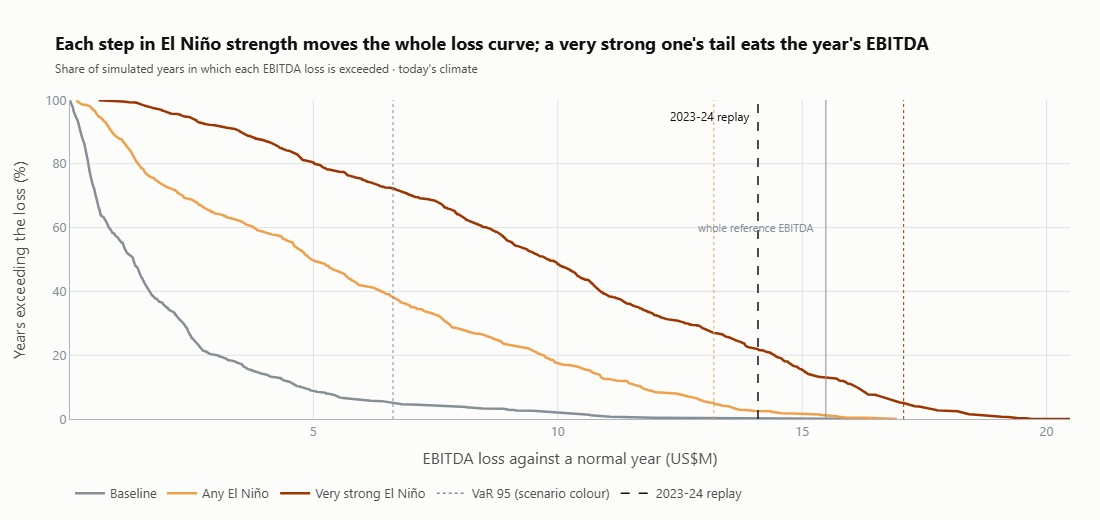

In [21]:
fig = go.Figure()
for name, d in scen.items():
    loss = np.sort(usd_m(d["loss_usd"].values))
    exceed = 1 - np.arange(1, len(loss) + 1) / len(loss)
    fig.add_trace(go.Scatter(x=loss, y=100 * exceed, mode="lines", line=dict(color=SCEN_COLORS[name], width=2.5), name=name,
                             hovertemplate="loss US$%{x:.1f}M exceeded in %{y:.1f}% of years<extra>" + name + "</extra>"))
    fig.add_vline(x=metrics_usd.loc[name, "VaR 95"], line=dict(color=SCEN_COLORS[name], dash="dot", width=1))
rp = usd_m(R["replay_2024"]["loss_usd"].iloc[0])
fig.add_vline(x=rp, line=dict(color=PALETTE["ink"], dash="dash", width=1.5))
fig.add_annotation(x=rp, y=95, text="2023-24 replay", showarrow=False, xshift=-48, font=dict(color=PALETTE["ink"], size=12))
fig.add_vline(x=usd_m(ref), line=dict(color=PALETTE["muted"], width=1))
fig.add_annotation(x=usd_m(ref), y=60, text="whole reference EBITDA", showarrow=False, xshift=-70, font=dict(color=PALETTE["muted"], size=11))
fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", line=dict(color=PALETTE["muted"], dash="dot", width=1.5), name="VaR 95 (scenario colour)"))
fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", line=dict(color=PALETTE["ink"], dash="dash", width=1.5), name="2023-24 replay"))
style_plot(fig, "Each step in El Niño strength moves the whole loss curve; a very strong one's tail eats the year's EBITDA",
           "Share of simulated years in which each EBITDA loss is exceeded · today's climate", height=520, width=1100)
fig.update_xaxes(title="EBITDA loss against a normal year (US$M)")
fig.update_yaxes(title="Years exceeding the loss (%)", range=[0, 100])
fig.show()

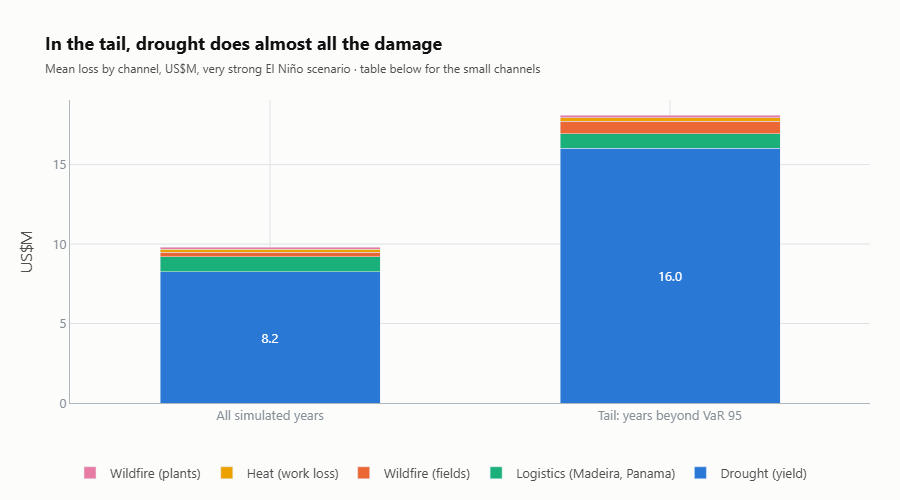

,All simulated years,Tail: years beyond VaR 95
Drought (yield),8.25,16.04
Wildfire (fields),0.28,0.77
"Logistics (Madeira, Panama)",0.96,0.91
Heat (work loss),0.20,0.22
Wildfire (plants),0.10,0.17


In [22]:
d = R["el_nino"]
var95 = metrics.loc["Very strong El Niño", "VaR 95"]
groups = {"All simulated years": d, "Tail: years beyond VaR 95": d[d["loss_usd"] >= var95]}
fig = go.Figure()
for c in ["loss_yield_usd", "loss_logistics_usd", "loss_fire_usd", "loss_labour_usd", "loss_plant_fire_usd"]:
    vals = [usd_m(g[c].mean()) for g in groups.values()]
    fig.add_trace(go.Bar(x=list(groups), y=vals, name=CHANNELS[c], marker=dict(color=CH_COLORS[CHANNELS[c]]),
                         text=[f"{v:.1f}" if v >= 2.0 else "" for v in vals], textposition="inside", insidetextanchor="middle"))
style_plot(fig, "In the tail, drought does almost all the damage", "Mean loss by channel, US$M, very strong El Niño scenario · table below for the small channels", height=500, width=900)
fig.update_layout(barmode="stack", bargap=0.45)
fig.update_yaxes(title="US$M")
fig.show()
contribution = pd.DataFrame({k: {CHANNELS[c]: usd_m(g[c].mean()) for c in order} for k, g in groups.items()})
display(contribution.round(2))

**Reading the results.** In a normal year today the company already loses a little against the reference, mostly from occasional dry seasons and the Madeira's falling low-water level. An El Niño of unknown strength already multiplies the expected loss; a very strong one shifts the whole curve further: the expected loss becomes more than half of the reference EBITDA, and in the worst 5% of years the loss exceeds the whole year's EBITDA. Knowing the strength of the event, not only that one is coming, is what separates a bad year from a broken one. The 2023-24 replay sits inside the El Niño distribution, not at its edge. Drought is the dominant channel on average and even more so in the tail; logistics adds a steady cost in almost every El Niño year, but it is not what breaks the year.

## 11. Decisions while there is still time

A number is only useful if it changes a decision. Two options are run through exactly the same simulated years, so the difference is the effect of the decision alone:

- **Diversify logistics:** ship 25% of the August to November volume in June and July, before low water, at an extra US$12/t for storage and working capital; and book 30% of volume on the Peru route in advance (against 20% on the spot market), at US$6 per booked tonne per year.
- **Transfer risk with parametric covers:** two index triggers, priced at the expected payout plus a 30% loading.
  - **River gauge cover:** pays when the Porto Velho gauge spends more than 20 days below 2 m between August and November, up to US$2M at 80 days.
  - **Drought index cover:** pays when the October to March season has more than one month of severe or extreme drought (SPEI-3), up to US$8M at four months.

A cover priced on a normal year is cheap. Once an El Niño is declared, an insurer will price it on the any El Niño scenario; once a very strong one is forecast, on the very strong scenario. All three prices are shown: the window for cheap protection closes step by step as the signal firms up.

In [23]:
def summarise(d, name, cost_note=""):
    t = tail(d)
    return {"option": name, "expected loss US$M": usd_m(t["expected loss"]), "VaR 95 US$M": usd_m(t["VaR 95"]), "ES 95 US$M": usd_m(t["ES 95"]),
            "mean EBITDA US$M": usd_m(d["ebitda_usd"].mean()), "cost": cost_note}

rows = []
for scen_key, scen_name in [("el_nino", "Very strong El Niño"), ("any_el_nino", "Any El Niño"), ("baseline", "Baseline")]:
    d0 = R[scen_key]
    rows.append({**summarise(d0, "No action"), "scenario": scen_name})
    div = R[f"{scen_key}_diversify"]
    rows.append({**summarise(div, "Diversify logistics", f"US${usd_m(div['decision_cost_usd'].iloc[0]):.2f}M per year"), "scenario": scen_name})
    for kind, label in [("gauge", "River gauge cover"), ("drought", "Drought index cover")]:
        for priced_on, when in [("baseline", "before any signal"), ("any_el_nino", "once an El Niño is declared"), ("el_nino", "once a very strong one is forecast")]:
            prem = sim.premium(R[priced_on], kind)
            covered = sim.transfer(d0, kind, prem)
            rows.append({**summarise(covered, f"{label} ({when})", f"premium US${usd_m(prem):.2f}M"), "scenario": scen_name})
decisions = pd.DataFrame(rows).set_index(["scenario", "option"])
display(decisions.round(2))

expected loss US$M  VaR 95 US$M  ES 95 US$M  mean EBITDA US$M               cost
scenario            option                                                                                                                              
Very strong El Niño No action                                                         9.79        17.08       18.13              5.70                   
                    Diversify logistics                                               9.52        16.89       17.90              5.96  US$0.07M per year
                    River gauge cover (before any signal)                             9.23        16.48       17.55              6.25   premium US$0.21M
                    River gauge cover (once an El Niño is declared)                   9.53        16.79       17.84              5.96   premium US$0.51M
                    River gauge cover (once a very strong one is fo...               10.01        17.26       18.33              5.47   premium US$0.99M
                    Drought index cover (before any signal)                           5.89         9.89       11.67              9.59   premium US$0.35M
                    Drought index cover (once an El Niño is declared)                 8.14        12.12       13.91              7.35   premium US$2.59M
                    Drought index cover (once a very strong one is ...               11.06        15.05       16.84              4.43   premium US$5.51M
Any El Niño         No action                                                         5.67        13.19       14.49              9.82                   
                    Diversify logistics                                               5.52        12.87       14.17              9.97  US$0.07M per year
                    River gauge cover (before any signal)                             5.49        12.69       13.84              9.99   premium US$0.21M
                    River gauge cover (once an El Niño is declared)                   5.79        12.98       14.14              9.70   premium US$0.51M
                    River gauge cover (once a very strong one is fo...                6.27        13.47       14.62              9.21   premium US$0.99M
                    Drought index cover (before any signal)                           4.02         7.70        8.90             11.46   premium US$0.35M
                    Drought index cover (once an El Niño is declared)                 6.27         9.92       11.14              9.22   premium US$2.59M
                    Drought index cover (once a very strong one is ...                9.19        12.83       14.06              6.30   premium US$5.51M
Baseline            No action                                                         2.02         6.63        9.65             13.47                   
                    Diversify logistics                                               1.96         6.61        9.55             13.53  US$0.07M per year
                    River gauge cover (before any signal)                             2.07         6.82        9.61             13.42   premium US$0.21M
                    River gauge cover (once an El Niño is declared)                   2.36         7.09        9.91             13.12   premium US$0.51M
                    River gauge cover (once a very strong one is fo...                2.85         7.60       10.39             12.64   premium US$0.99M
                    Drought index cover (before any signal)                           2.10         5.26        6.92             13.39   premium US$0.35M
                    Drought index cover (once an El Niño is declared)                 4.34         7.48        9.16             11.14   premium US$2.59M
                    Drought index cover (once a very strong one is ...                7.26        10.39       12.09              8.22   premium US$5.51M

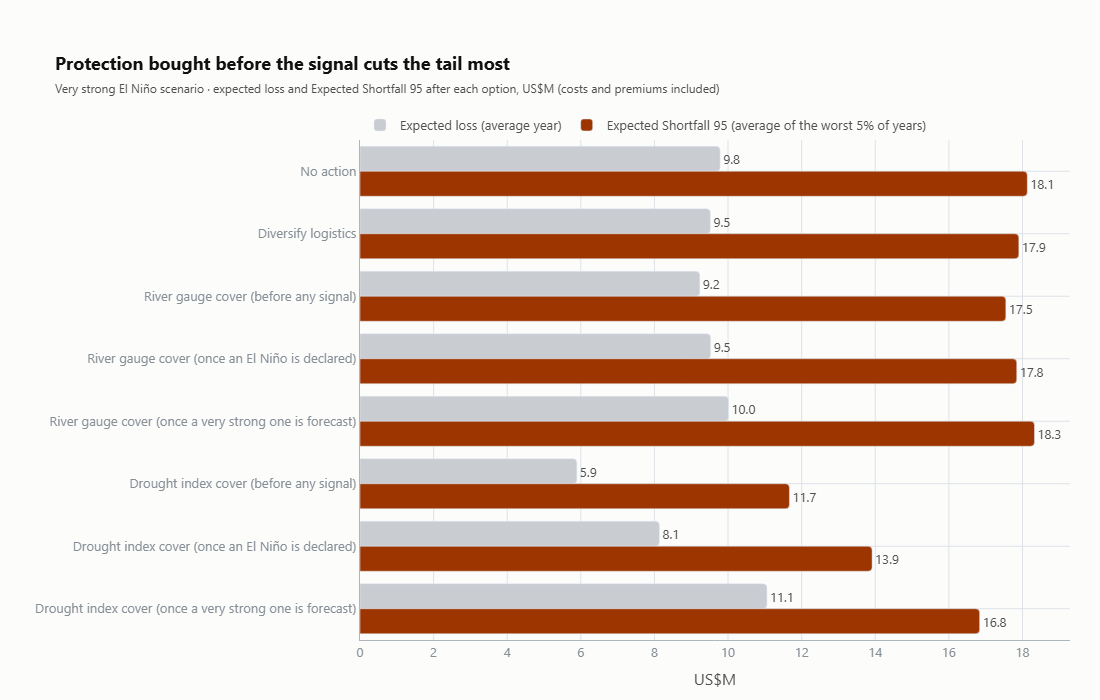

In [24]:
d_el = decisions.loc["Very strong El Niño"]
fig = go.Figure()
for metric, label, color in [("expected loss US$M", "Expected loss (average year)", "#c9ccd1"),
                             ("ES 95 US$M", "Expected Shortfall 95 (average of the worst 5% of years)", SCEN_COLORS["Very strong El Niño"])]:
    fig.add_trace(go.Bar(y=d_el.index, x=d_el[metric], orientation="h", name=label, marker=dict(color=color, cornerradius=4),
                         text=[f"{v:.1f}" for v in d_el[metric]], textposition="outside"))
style_plot(fig, "Protection bought before the signal cuts the tail most",
           "Very strong El Niño scenario · expected loss and Expected Shortfall 95 after each option, US$M (costs and premiums included)", height=560, width=1100)
fig.update_layout(barmode="group", margin=dict(l=360, t=140), height=700, legend=dict(orientation="h", yanchor="bottom", y=1.0, xanchor="left", x=0))
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title="US$M")
fig.show()

**Reading the decisions.** Diversifying logistics is cheap and removes part of the river cost, but it cannot touch the drought loss that dominates the tail. The river gauge cover behaves the same way. The drought index cover addresses the channel that matters and, bought at a normal-year price, cuts the tail sharply. Bought once an El Niño is declared, the same cover already costs several times more; bought once a very strong one is forecast, it leaves the expected loss worse than doing nothing. Timing is the decision: the protection is worth buying before the signal is in the price. Whatever is not transferred is the amount to provision for, or to hold as a liquidity buffer for the 2027 export year.

## 12. Traceability and sources

| Channel | Data | Model |
|---|---|---|
| El Niño strength | NOAA Oceanic Niño Index, 1950-2026; NOAA CPC outlook, 10 Sep 2026 | Event classes by ONI peak |
| Scenarios | All series below, seasons 1986-2024 | Delta change against neutral years, trends restated to today, 1,000 simulated years per scenario |
| Drought → yield | Alpha-Klima SPEI-3 at the fields; IBGE municipal coffee yields | Drought months by category in Oct-Mar, calibrated on coffee's record in very strong El Niños |
| Wildfire → fields and plants | MODIS burned area; Alpha-Klima Fire Weather Index | Burned share loses that year's harvest; Alpha-Klima generic fire damage curve for plants |
| Heat → staff | ERA5-Land temperature and humidity at the plants | Alpha-Klima WBGT work-loss model, change against a normal year |
| Madeira → logistics | ANA Porto Velho gauge, 1967-2025 | Barge capacity and cost by river stage; navigation limits from the Brazilian Navy and industry reports |
| Panama → logistics | Panama Canal Authority operations record; ERA5-Land rainfall | Normal, moderate and severe canal states |
| Financials | Case economics and routes | Least-cost routing, EBITDA per simulated year, VaR and ES as in Alpha-Klima's financial module |
| Decisions | Same simulated years | Illustrative logistics costs; parametric premium = expected payout × 1.3 |

Plant values, the labour cost split and decision costs are case assumptions.

### Sources

- **El Niño:** NOAA PSL, [Oceanic Niño Index](https://psl.noaa.gov/data/correlation/oni.data); NOAA CPC, [ENSO diagnostic discussion](https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso_advisory/ensodisc.shtml), 10 September 2026.
- **Climate data:** Alpha-Klima's climate data store (SPEI and Fire Weather Index computed by Alpha-Klima; ERA5-Land from the Copernicus Climate Change Service / ECMWF; MODIS MCD64A1 burned area from NASA); ANA, [HidroWeb telemetry](https://telemetriaws1.ana.gov.br/ServiceANA.asmx), Porto Velho gauge 15400000.
- **Coffee yields:** IBGE, Produção Agrícola Municipal, [SIDRA table 1613](https://apisidra.ibge.gov.br/values/t/1613/n3/11/v/216,214,112,215/p/2012-2024/c82/31620).
- **Drought and yield:** Miyamoto & Hackmann (2025), [Discover Agriculture 3:246](https://doi.org/10.1007/s44279-025-00425-y); Parisoto et al. (2026), [Atmosphere 17:367](https://doi.org/10.3390/atmos17040367); Arruda & Grande (2003), [Bragantia 62:139-145](https://doi.org/10.1590/S0006-87052003000100017); Luong & Bui (2025), [Journal of Agricultural Meteorology 81:171-183](https://doi.org/10.2480/agrmet.D-24-00055).
- **Scenario method:** delta change, e.g. Teutschbein & Seibert (2012), [Journal of Hydrology 456-457:12-29](https://doi.org/10.1016/j.jhydrol.2012.05.052).
- **Madeira navigation:** Brazilian Navy, Porto Velho river captaincy, [Ordinance 53/CFPV of 1 August 2023](https://assets.marinha.mil.br/cfpv/sites/www.marinha.mil.br.cfpv/files/port-53-2023-cfpv-proibicao_navegacao_noturna-pvh_passagem-urua-extra-mb.pdf), restrictions below 4 m; [CNN Brasil](https://www.cnnbrasil.com.br/economia/seu-bolso/meu-dinheiro/seca-suspende-transporte-de-graos-no-rio-madeira-e-eleva-custos-na-exportacao/) and [NorthStandard](https://north-standard.com/insights-and-resources/resources/news/madeira-river-experiencing-drought), suspension depth and barge loads.
- **Panama Canal:** Panama Canal Authority, [advisory of 20 August 2026](https://pancanal.com/en/panama-canal-adopts-additional-measures-to-address-reduced-precipitation-in-the-canal-watershed/), [El Niño draft restrictions of 2015](https://pancanal.com/en/to-mitigate-effects-of-el-nino-phenomenon-the-panama-canal-announces-draft-restrictions-to-transiting-vessels/), [water measures of 2020](https://pancanal.com/en/panama-canal-secures-steady-draft-operational-reliability-following-water-measures/) and [freshwater management](https://pancanal.com/en/how-the-canal-manages-the-fresh-water-challenge/); [gCaptain, June 2016](https://gcaptain.com/rain-helps-panama-canal-authority-lift-draft-restrictions/); [Maritime Executive](https://maritime-executive.com/article/panama-canal-plans-to-cut-transits-by-40-due-to-ongoing-drought) and [project44](https://www.project44.com/supply-chain-insights/recovery-of-the-panama-canal/), 2023-24 transits.